# 1. First steps: crashes onto a grid, then onto districts

urbanweave moves data from where it was collected to the places an analysis asks about. Every step
has the same two parts:

1. **`uw.match(sources, targets, method)`** decides who goes where, and with what quantities (an
   allocation fraction, an overlap area or length, a distance, a sampling weight).
2. **`uw.aggregate(matches, values, reductions)`** turns the matched values into one row per target.

Both steps attach a **report**: what was matched, what was left out and why, and how totals moved.
This notebook walks through one complete example on *Riverton*, a synthetic town of 3 km × 2 km
that ships with the tutorials, so nothing needs downloading.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly
import diagrams                     # schematic figures of the concepts

## Crashes from a table

City portals publish crashes as tables with latitude and longitude. `points_from_columns` turns
such a table into points and drops rows whose coordinates are missing or out of range, counting
them by cause.

In [2]:
table = td.crashes_table()
table.head()

,crash_id,persons_injured,hour,severity,latitude,longitude
0,C0000,0,1,property,40.657162,-74.988195
1,C0001,0,7,property,40.650790,-74.999213
2,C0002,0,13,property,40.651812,-74.999968
3,C0003,2,23,serious,40.655545,-75.005924
4,C0004,0,18,property,40.657589,-75.010443


In [3]:
crashes = uw.points_from_columns(table, lat="latitude", lon="longitude")
print(len(crashes), "points in", crashes.crs.name, "| dropped:", crashes.attrs.get("urbanweave_dropped", {}))

600 points in WGS 84 | dropped: {'missing_coordinates': 0, 'not_numeric': 0, 'not_finite': 0, 'out_of_range': 0}


## A grid of H3 cells

H3 is a hexagonal grid: a raster whose cells have IDs. `uw.targets.h3_cells` builds the cells at a
resolution over an extent. Like UrbanTrace, it selects the cells whose **centers** fall inside the
extent's bounding box, so points near the edge can land in a cell that is not part of the grid.
Resolution 9 cells are about 0.1 km².

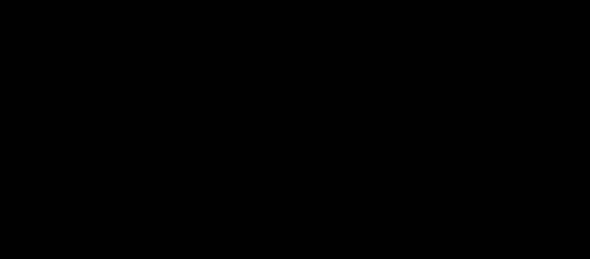

In [4]:
diagrams.h3_support()

In [5]:
cells = uw.targets.h3_cells(crashes, 9)
print(len(cells), "cells")
cells.head(3)

52 cells


,target_id,geometry
0,892a12a9803ffff,"POLYGON ((-74.98655 40.65683, -74.98863 40.655..."
1,892a12a9807ffff,"POLYGON ((-74.98426 40.65427, -74.98634 40.653..."
2,892a12a980bffff,"POLYGON ((-74.99082 40.65668, -74.9929 40.6557..."


## Match, then aggregate

`contain` assigns each point to the cell containing it; for H3 targets this is an index lookup, not
a geometric test. `source_id="crash_id"` names the column that identifies each crash, so the
pairs and reports speak in crash IDs.

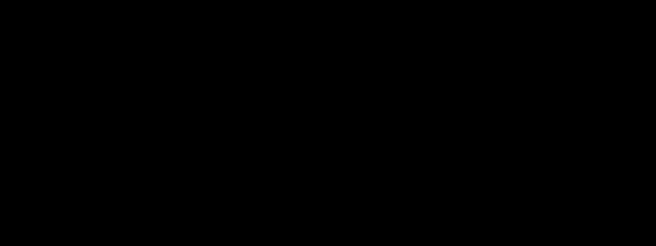

In [6]:
diagrams.match_and_aggregate()

In [7]:
m = uw.match(crashes, cells, "contain", source_id="crash_id")
m.pairs.head()

,source_id,target_id,allocation_fraction,sample_weight
0,C0006,892a12a9803ffff,1.0,1.0
1,C0084,892a12a9803ffff,1.0,1.0
2,C0090,892a12a9803ffff,1.0,1.0
3,C0129,892a12a9803ffff,1.0,1.0
4,C0196,892a12a9803ffff,1.0,1.0


In [8]:
grid = uw.aggregate(m, None, [
    uw.count(as_="crashes", fill_empty=0),                         # cells with no crash get 0, not missing
    uw.sum("persons_injured", as_="injured", fill_empty=0),
])
grid[["target_id", "crashes", "injured"]].sort_values("crashes", ascending=False).head()

,target_id,crashes,injured
42,892a12a9ab7ffff,46,19
21,892a12a987bffff,39,23
39,892a12a9aabffff,32,8
19,892a12a9873ffff,30,15
37,892a12a9aa3ffff,27,14


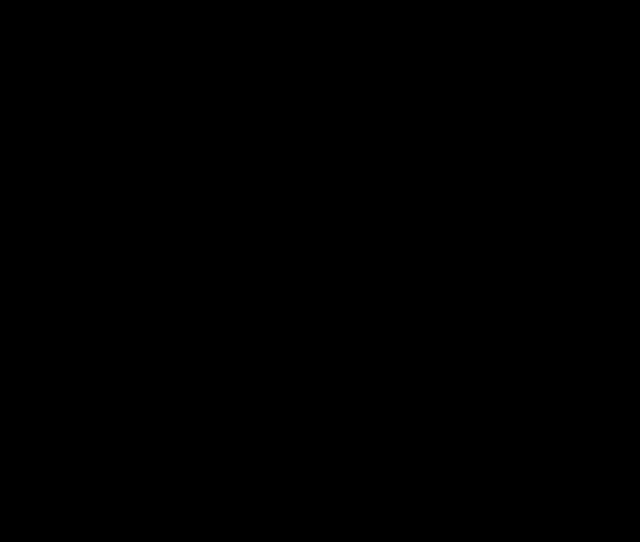

In [9]:
districts = td.districts()
(Map("Crashes per H3 cell (resolution 9)")
 .fill(grid, "crashes", legend="crashes per cell", tooltip=["injured"])
 .outline(districts, label="name")
 .dots(crashes, radius=1.4)
 .note("Hover a cell for its ID and counts. Riverton is synthetic."))

## What the report says

The report travels with the result (`uw.report_of`). Here it says that 11 crashes were not matched:
they lie in cells whose centers fall outside the grid's extent. It also says how the injury total
moved: what came in, what was matched, and what was allocated to cells.

In [10]:
report = uw.report_of(grid)
show(report["match"]["sources"])

{
 "total": 600,
 "eligible": 600,
 "excluded": {},
 "matched": 589,
 "unmatched": {
  "outside_support": {
   "count": 11,
   "sample": ["C0112", "C0126", "C0220", "C0231", "C0259", "C0341", "C0348", "C0360", "C0401", "C0504"]
  }
 }
}


In [11]:
show(report["aggregate"][1]["extensive"])

{
 "valid_input": 272.0,
 "matched_input": 268.0,
 "unmatched_input": 4.0,
 "allocated": 268.0,
 "unallocated": 4.0
}


## From cells to districts

The grid is now a source in its own right: each cell carries its counts. `area_overlap` splits each
cell among the districts it overlaps, in proportion to area, measured in metres in a local UTM
zone. The counts that reach the districts add up to what the cells held, less the share of cells
lying outside every district.

In [11]:
by_district = uw.aggregate(
    uw.match(grid, districts, "area_overlap", target_id="district_id"),
    None,
    [uw.sum("crashes", as_="crashes"), uw.sum("injured", as_="injured"), uw.density("crashes", as_="crashes_per_km2")],
)
by_district[["district_id", "name", "crashes", "injured", "crashes_per_km2"]].round(1)

,district_id,name,crashes,injured,crashes_per_km2
0,NG,Northgate,123.3,52.1,99.2
1,OT,Old Town,204.1,95.7,201.6
2,EF,Eastfield,86.1,48.1,75.7
3,MD,Mill District,71.9,32.8,53.3
4,RS,Riverside,98.6,37.8,78.3


In [12]:
show(uw.report_of(by_district)["aggregate"][0]["extensive"])

{
 "valid_input": 589.0,
 "matched_input": 589.0,
 "unmatched_input": 0.0,
 "allocated": 584.0424447142468,
 "unallocated": 4.9575552857531875
}


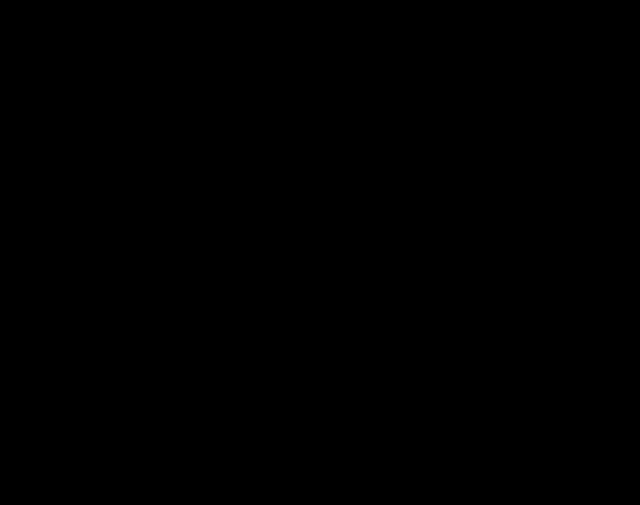

In [13]:
(Map("Crashes per km², by district")
 .fill(by_district, "crashes_per_km2", legend="crashes per km²", tooltip=["name", "crashes"])
 .outline(districts, label="name"))

## Every operator, described by the registry

`uw.registry()` describes every installed operator: what geometries it accepts, its parameters
with defaults and units, the quantities it produces and the reductions that suit it. It is generated
from the code that runs the operators, so it cannot drift from them.

In [14]:
reg = uw.registry()
sorted(reg["matching"])

['area_overlap',
 'centroid',
 'contain',
 'gaussian',
 'largest_overlap',
 'length_weighted',
 'nearest',
 'nearest_node',
 'nearest_segment',
 'polygon_to_lines',
 'representative_point',
 'sample',
 'within_distance']

In [15]:
show({k: reg["matching"]["area_overlap"][k] for k in ("summary", "sources", "targets", "match_quantities", "assignment")})

{
 "summary": "Each target receives its overlap with each source: the area in m² and the share of the source's area.",
 "sources": ["Polygon", "MultiPolygon"],
 "targets": ["Polygon", "MultiPolygon"],
 "match_quantities": ["allocation_fraction", "overlap_measure"],
 "assignment": "independent"
}


**Next:** [2. Matching methods](02_matching_methods.ipynb) compares the ways sources can be
matched to targets.